# H&M Customer Segmentation: RFM Analysis & Clustering

This notebook analyzes customer purchase behavior using the H&M Personalized 
Fashion Recommendations dataset (Kaggle, 2022). We construct RFM (Recency, 
Frequency, Monetary) scores for 1.3M customers, apply PCA and k-means clustering 
to identify natural customer segments, and enrich each segment with product 
category preferences.

**Dataset:** 31.8M transactions · 1.4M customers · 105K articles · Sept 2018 – Sept 2020

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Plot styling
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

## Data Loading

We load three core tables: transactions, customers, and articles. 
Transactions contain 31.8M purchase records; customers contain demographic 
and marketing attributes for 1.4M shoppers; articles contain product metadata 
for 105K items.

In [30]:
transactions = pd.read_csv('data/transactions_clean.csv', parse_dates=['t_dat'])
customers = pd.read_csv('data/customers.csv')
articles = pd.read_csv('data/articles.csv')

print(f"Transactions: {transactions.shape}")
print(f"Customers: {customers.shape}")
print(f"Articles: {articles.shape}")
print(f"Date range: {transactions['t_dat'].min().date()} to {transactions['t_dat'].max().date()}")

Transactions: (31788324, 5)
Customers: (1371980, 7)
Articles: (105542, 25)
Date range: 2018-09-20 to 2020-09-22


## RFM Construction

RFM (Recency, Frequency, Monetary) is a classic customer analytics framework 
that characterizes each customer along three behavioral dimensions:

- **Recency**: Days since last purchase (lower = more recently active)
- **Frequency**: Total number of transactions
- **Monetary**: Total amount spent

Rather than collapsing these into a single score immediately, we retain the 
raw values for PCA and clustering, which allows us to identify natural groupings 
in the data without imposing arbitrary score cutoffs.

In [34]:
snapshot_date = transactions['t_dat'].max() + pd.Timedelta(days=1)

rfm = transactions.groupby('customer_id').agg(
    recency=('t_dat', lambda x: (snapshot_date - x.max()).days),
    frequency=('article_id', 'count'),
    monetary=('price', 'sum')  
).reset_index()

# Join customer attributes
rfm = rfm.merge(
    customers[['customer_id', 'age', 'fashion_news_frequency', 'club_member_status']], 
    on='customer_id', how='left'
)

print(rfm.shape)
print(rfm[['recency', 'frequency', 'monetary']].describe())

(1362281, 7)
            recency     frequency      monetary
count  1.362281e+06  1.362281e+06  1.362281e+06
mean   2.361484e+02  2.333463e+01  6.493858e-01
std    2.211188e+02  3.924225e+01  1.197582e+00
min    1.000000e+00  1.000000e+00  7.627119e-04
25%    4.900000e+01  3.000000e+00  8.806780e-02
50%    1.520000e+02  9.000000e+00  2.455932e-01
75%    3.990000e+02  2.700000e+01  7.011864e-01
max    7.340000e+02  1.895000e+03  5.767641e+01


## Exploratory Analysis of RFM Features

Before reducing dimensions, we examine the correlations between R, F, and M. 
Strong correlations would suggest redundancy; weak correlations suggest each 
dimension captures distinct customer behavior.

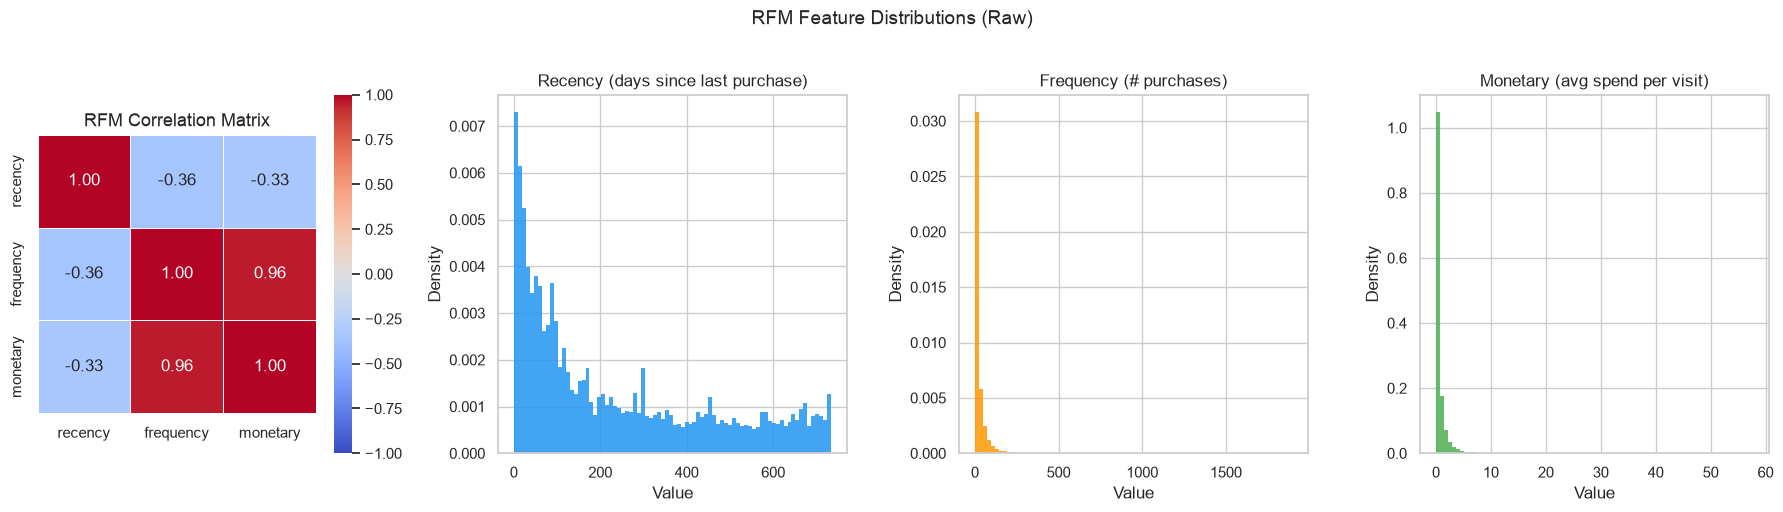

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Correlation heatmap
corr = rfm[['recency', 'frequency', 'monetary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            ax=axes[0])
axes[0].set_title('RFM Correlation Matrix', fontsize=13)

# One histogram per feature
for i, (col, color, label) in enumerate(zip(
    ['recency', 'frequency', 'monetary'],
    ['#2196F3', '#FF9800', '#4CAF50'],
    ['Recency (days since last purchase)', 'Frequency (# purchases)', 'Monetary (avg spend per visit)']
)):
    axes[i+1].hist(rfm[col], bins=80, color=color, density=True, edgecolor='none', alpha=0.85)
    axes[i+1].set_title(label, fontsize=12)
    axes[i+1].set_xlabel('Value')
    axes[i+1].set_ylabel('Density')

plt.suptitle('RFM Feature Distributions (Raw)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

We can see a strong positive correlation between monetary and frequency. This is expected as monetary is computed as the sum of amount spent across purchases (if a shopper is purchasing more frequenty, they will have spent more money). Additionally, there is a moderage negative correlation between frequency and recency (if a customer shops often, their last purchase was more recent).

These correlations limit the performance of PCA and make our features less informative. We can reduce redundancy by computing monetary as the mean instead of the sum. For recency, we can residualize recency on frequency. Recency will now reflect customers who are more or less recent than we would expect given their frequency. 

In [39]:
snapshot_date = transactions['t_dat'].max() + pd.Timedelta(days=1)

rfm = transactions.groupby('customer_id').agg(
    recency=('t_dat', lambda x: (snapshot_date - x.max()).days),
    frequency=('article_id', 'count'),
    monetary=('price', 'mean')  # avg spend per transaction (avoids collinearity with frequency)
).reset_index()

# Residualize recency on frequency to remove spurious negative correlation
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(rfm[['frequency']], rfm['recency'])
rfm['recency_resid'] = rfm['recency'] - lr.predict(rfm[['frequency']])

# Join customer attributes
rfm = rfm.merge(
    customers[['customer_id', 'age', 'fashion_news_frequency', 'club_member_status']], 
    on='customer_id', how='left'
)

print(rfm.shape)
print(rfm[['recency', 'recency_resid', 'frequency', 'monetary']].describe())

(1362281, 8)
            recency  recency_resid     frequency      monetary
count  1.362281e+06   1.362281e+06  1.362281e+06  1.362281e+06
mean   2.361484e+02   1.864013e-14  2.333463e+01  2.875476e-02
std    2.211188e+02   2.064251e+02  3.924225e+01  1.429338e-02
min    1.000000e+00  -2.802592e+02  1.000000e+00  7.627119e-04
25%    4.900000e+01  -1.681406e+02  3.000000e+00  2.095763e-02
50%    1.520000e+02  -6.564641e+01  9.000000e+00  2.613317e-02
75%    3.990000e+02   1.500733e+02  2.700000e+01  3.336083e-02
max    7.340000e+02   3.552179e+03  1.895000e+03  5.067797e-01


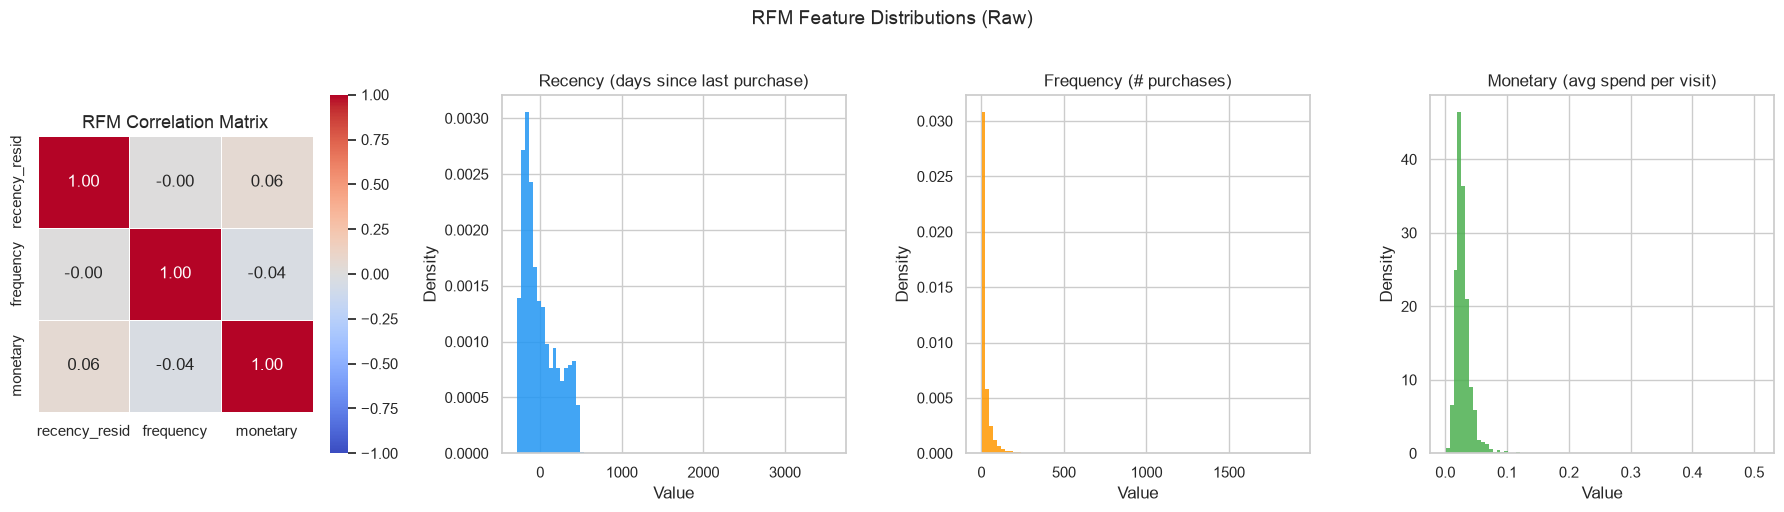

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Correlation heatmap
corr = rfm[['recency_resid', 'frequency', 'monetary']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5,
            ax=axes[0])
axes[0].set_title('RFM Correlation Matrix', fontsize=13)

# One histogram per feature
for i, (col, color, label) in enumerate(zip(
    ['recency_resid', 'frequency', 'monetary'],
    ['#2196F3', '#FF9800', '#4CAF50'],
    ['Recency (days since last purchase given frequency)', 'Frequency (# purchases)', 'Monetary (avg spend per visit)']
)):
    axes[i+1].hist(rfm[col], bins=80, color=color, density=True, edgecolor='none', alpha=0.85)
    axes[i+1].set_title(label, fontsize=12)
    axes[i+1].set_xlabel('Value')
    axes[i+1].set_ylabel('Density')

plt.suptitle('RFM Feature Distributions (Raw)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

We have successfully decorrelated our features and can now move forward with our analysis.

## Preprocessing: Log Transform & Standardization

Frequency and monetary value are heavily right-skewed due to a small number 
of extremely active customers. We apply a log(x+1) transform to compress these 
tails before standardizing all three dimensions to mean=0, std=1. This ensures 
PCA treats each dimension equally regardless of original scale.

In [41]:
rfm_model = rfm[['recency_resid', 'frequency', 'monetary']].copy()

# Log transform skewed dimensions (recency_resid can be negative so we skip it)
rfm_model['frequency'] = np.log1p(rfm_model['frequency'])
rfm_model['monetary'] = np.log1p(rfm_model['monetary'])

# Standardize
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_model)
rfm_scaled = pd.DataFrame(rfm_scaled, columns=['recency_resid', 'frequency', 'monetary'])

print(rfm_scaled.describe().round(3))

       recency_resid    frequency     monetary
count    1362281.000  1362281.000  1362281.000
mean          -0.000       -0.000       -0.000
std            1.000        1.000        1.000
min           -1.358       -1.476       -2.032
25%           -0.815       -0.892       -0.555
50%           -0.318       -0.121       -0.182
75%            0.727        0.745        0.337
max           17.208        4.292       28.206


## PCA: Reducing RFM to Two Dimensions

We apply PCA to the standardized RFM matrix to project customers into a 
2D space for visualization. With only three input dimensions, two principal 
components will capture most of the variance while allowing us to plot every 
customer as a point.

In [42]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]:.1%}")
print(f"Variance explained by PC2: {pca.explained_variance_ratio_[1]:.1%}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.1%}")
print(f"\nPC1 loadings: recency={pca.components_[0,0]:.3f}, frequency={pca.components_[0,1]:.3f}, monetary={pca.components_[0,2]:.3f}")
print(f"PC2 loadings: recency={pca.components_[1,0]:.3f}, frequency={pca.components_[1,1]:.3f}, monetary={pca.components_[1,2]:.3f}")

Variance explained by PC1: 44.1%
Variance explained by PC2: 31.8%
Total variance explained: 75.9%

PC1 loadings: recency=-0.617, frequency=0.677, monetary=-0.401
PC2 loadings: recency=-0.458, frequency=0.106, monetary=0.883


## PCA Visualization

We plot a random sample of 50,000 customers in PCA space. PC1 captures overall 
customer value (frequency + monetary, inverse recency); PC2 captures recency 
independent of value.

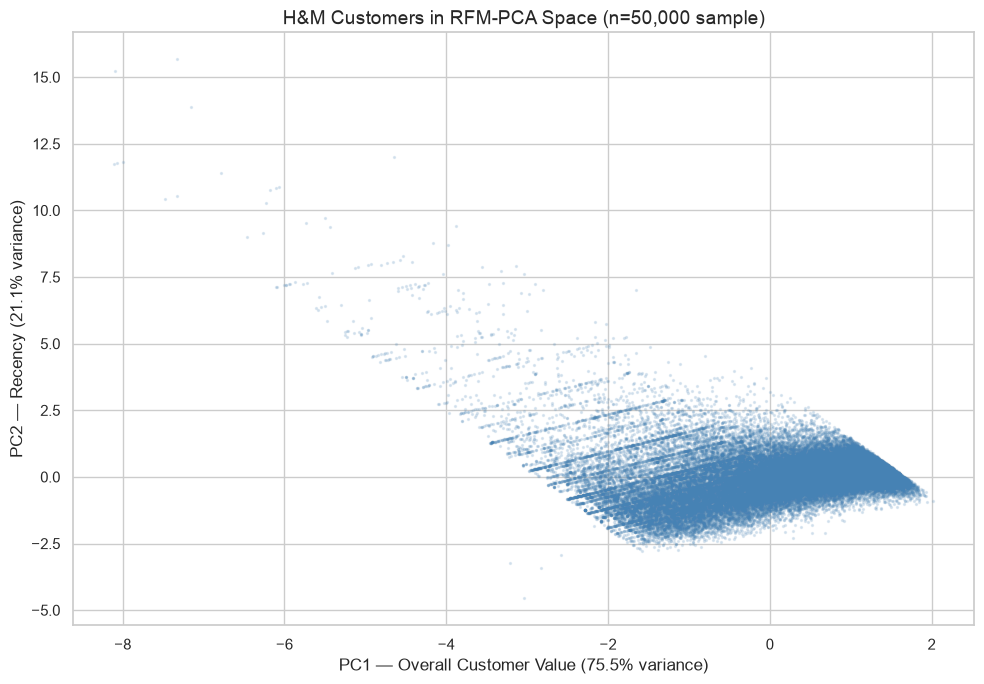

In [43]:
# Sample for plotting
np.random.seed(42)
sample_idx = np.random.choice(len(rfm_pca), size=50000, replace=False)

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    rfm_pca[sample_idx, 0], 
    rfm_pca[sample_idx, 1],
    alpha=0.15, s=2, c='steelblue'
)

ax.set_xlabel(f'PC1 — Overall Customer Value (75.5% variance)', fontsize=12)
ax.set_ylabel(f'PC2 — Recency (21.1% variance)', fontsize=12)
ax.set_title('H&M Customers in RFM-PCA Space (n=50,000 sample)', fontsize=14)
plt.tight_layout()
plt.show()

## K-Means Clustering

We use the silhouette score to select the optimal number of clusters k, 
then fit k-means on the full standardized RFM matrix and visualize the 
resulting clusters in PCA space.

In [44]:
# Test k=2 through 8 on a sample for speed
sample_idx_km = np.random.choice(len(rfm_scaled), size=100000, replace=False)
rfm_sample = rfm_scaled.iloc[sample_idx_km]

silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_sample)
    score = silhouette_score(rfm_sample, labels, sample_size=10000)
    silhouette_scores.append(score)
    print(f"k={k}: silhouette={score:.4f}")

k=2: silhouette=0.3571
k=3: silhouette=0.3725
k=4: silhouette=0.3387
k=5: silhouette=0.3374
k=6: silhouette=0.3010
k=7: silhouette=0.2855
k=8: silhouette=0.2923


## Fitting K-Means (k=3)

We fit k-means on the full standardized RFM matrix and 
project the clusters into PCA space for visualization.

In [45]:
# Fit on full dataset
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm['cluster'] = kmeans.fit_predict(rfm_scaled).astype(int)

# Add PCA coordinates
rfm['pc1'] = rfm_pca[:, 0]
rfm['pc2'] = rfm_pca[:, 1]

print(rfm['cluster'].value_counts().sort_index())

cluster
0    119561
1    831603
2    411117
Name: count, dtype: int64


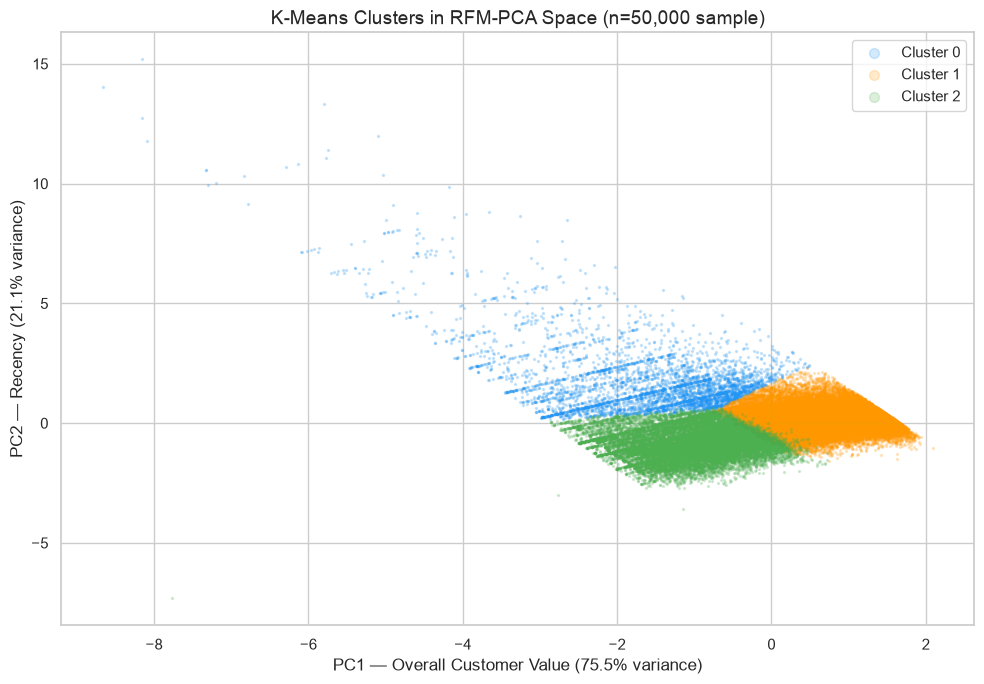

In [46]:
cluster_colors = {0: '#2196F3', 1: '#FF9800', 2: '#4CAF50'}
cluster_labels = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2'}

fig, ax = plt.subplots(figsize=(10, 7))

sample_idx = np.random.choice(len(rfm), size=50000, replace=False)
rfm_sample = rfm.iloc[sample_idx]

for cluster_id in sorted(rfm['cluster'].unique()):
    mask = rfm_sample['cluster'] == cluster_id
    ax.scatter(
        rfm_sample.loc[mask, 'pc1'],
        rfm_sample.loc[mask, 'pc2'],
        alpha=0.2, s=2,
        c=cluster_colors[cluster_id],
        label=cluster_labels[cluster_id]
    )

ax.set_xlabel('PC1 — Overall Customer Value (75.5% variance)', fontsize=12)
ax.set_ylabel('PC2 — Recency (21.1% variance)', fontsize=12)
ax.set_title('K-Means Clusters in RFM-PCA Space (n=50,000 sample)', fontsize=14)
ax.legend(markerscale=5, fontsize=11)
plt.tight_layout()
plt.show()

## Cluster Profiles

In order to characterize our clusters, we examine their size and RFM characteristics.

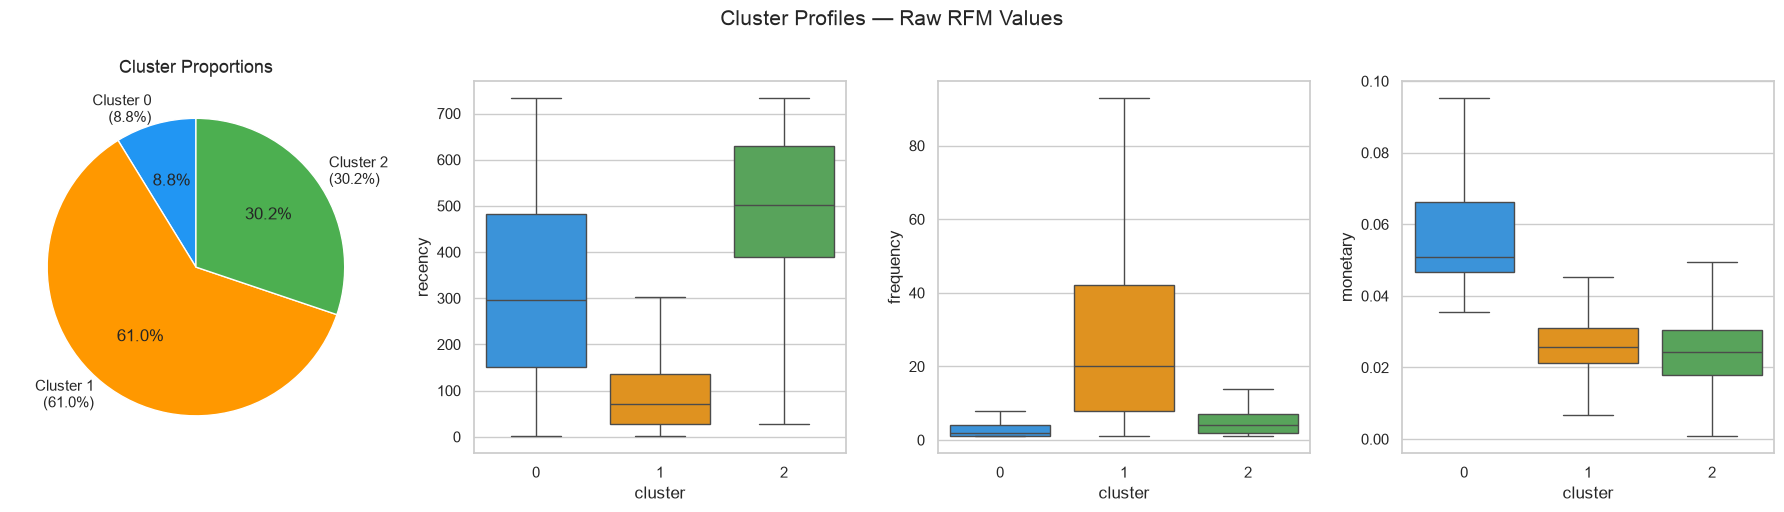

         recency  frequency  monetary
cluster                              
0          297.0        2.0      0.05
1           70.0       20.0      0.03
2          502.0        4.0      0.02


In [47]:
# --- Cluster sizes ---
cluster_counts = rfm['cluster'].value_counts().sort_index()
cluster_pct = (cluster_counts / len(rfm) * 100).round(1)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Pie chart
axes[0].pie(cluster_counts, labels=[f'Cluster {i}\n({cluster_pct[i]}%)' for i in range(3)],
            colors=['#2196F3', '#FF9800', '#4CAF50'],
            autopct='%1.1f%%', startangle=90)
axes[0].set_title('Cluster Proportions', fontsize=13)

# RFM boxplots per cluster
rfm_plot = rfm[['recency', 'frequency', 'monetary', 'cluster']].copy()
rfm_plot['cluster'] = rfm_plot['cluster'].astype(int)

palette_list = ['#2196F3', '#FF9800', '#4CAF50']

for i, metric in enumerate(['recency', 'frequency', 'monetary']):
    sns.boxplot(data=rfm_plot, x='cluster', y=metric, hue='cluster',
            palette=palette_list, legend=False,
            ax=axes[i+1], showfliers=False)

plt.suptitle('Cluster Profiles — Raw RFM Values', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

# Numeric summary
print(rfm.groupby('cluster')[['recency', 'frequency', 'monetary']].median().round(2))

In [48]:
cluster_names = {1: 'Loyalists', 0: 'High-Value Occasionals', 2: 'Lapsed'}
rfm['segment'] = rfm['cluster'].map(cluster_names)
print(rfm['segment'].value_counts())

segment
Loyalists                 831603
Lapsed                    411117
High-Value Occasionals    119561
Name: count, dtype: int64


## Product Category Preferences by Segment

We merge the cluster assignments back to transactions and articles to identify 
which product categories each segment over- or under-indexes on relative to 
the overall customer base.

In [49]:
# Merge segment labels onto transactions
transactions_seg = transactions.merge(
    rfm[['customer_id', 'segment']], on='customer_id', how='inner'
)

# Merge article metadata to get product group
transactions_seg = transactions_seg.merge(
    articles[['article_id', 'product_group_name']], on='article_id', how='left'
)

# Count transactions per segment x product group
cat_seg = (transactions_seg
    .groupby(['segment', 'product_group_name'])
    .size()
    .reset_index(name='n_transactions')
)

# Compute share within each segment
cat_seg['seg_total'] = cat_seg.groupby('segment')['n_transactions'].transform('sum')
cat_seg['pct_of_segment'] = cat_seg['n_transactions'] / cat_seg['seg_total'] * 100

# Also compute overall share (baseline)
overall = (transactions_seg
    .groupby('product_group_name')
    .size()
    .reset_index(name='n_total')
)
overall['pct_overall'] = overall['n_total'] / overall['n_total'].sum() * 100

# Merge and compute index (how much over/under baseline)
cat_seg = cat_seg.merge(overall[['product_group_name', 'pct_overall']], on='product_group_name')
cat_seg['index'] = (cat_seg['pct_of_segment'] / cat_seg['pct_overall'] * 100).round(1)

print(cat_seg.shape)
print(cat_seg['product_group_name'].nunique(), "product groups")

(54, 7)
19 product groups


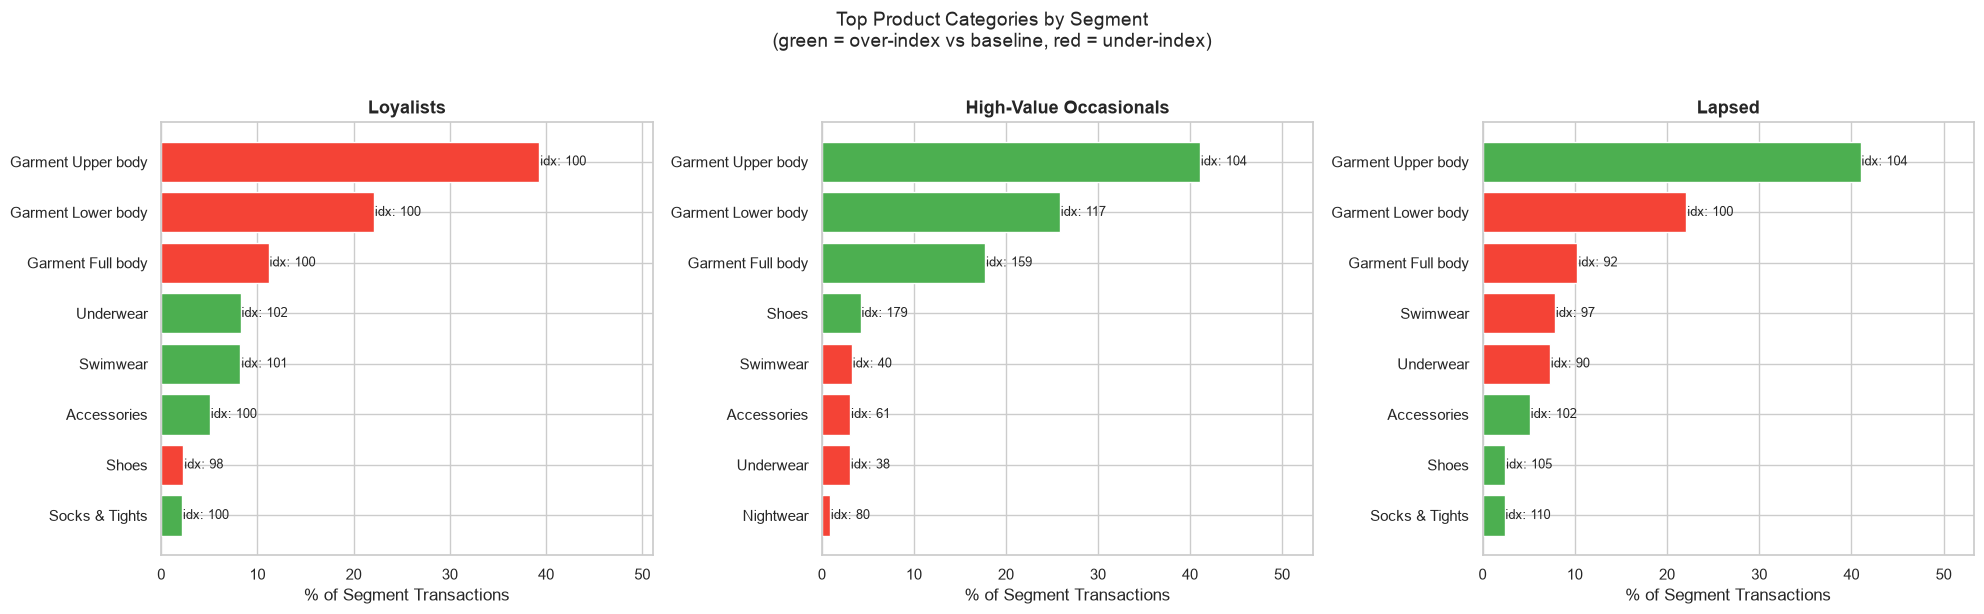

In [50]:
top_n = 8
segments = ['Loyalists', 'High-Value Occasionals', 'Lapsed']

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

for ax, seg in zip(axes, segments):
    data = (cat_seg[cat_seg['segment'] == seg]
            .nlargest(top_n, 'pct_of_segment')
            .sort_values('pct_of_segment'))
    
    colors = ['#4CAF50' if x >= 100 else '#F44336' for x in data['index']]
    
    bars = ax.barh(data['product_group_name'], data['pct_of_segment'], color=colors)
    
    # Add index labels on bars
    for bar, idx in zip(bars, data['index']):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
                f'idx: {idx:.0f}', va='center', fontsize=9)
    
    ax.set_title(seg, fontsize=13, fontweight='bold')
    ax.set_xlabel('% of Segment Transactions')
    ax.set_xlim(0, data['pct_of_segment'].max() * 1.3)

plt.suptitle('Top Product Categories by Segment\n(green = over-index vs baseline, red = under-index)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Transaction Share by Category

Across all three segments, Garment Upper Body dominates transaction share (~40%), 
followed by Garment Lower Body (~22%) and Garment Full Body (~10–18%). The category 
mix is broadly similar across segments, suggesting that *what* customers buy does 
not differ dramatically by segment — but *how much they spend* when they buy does.

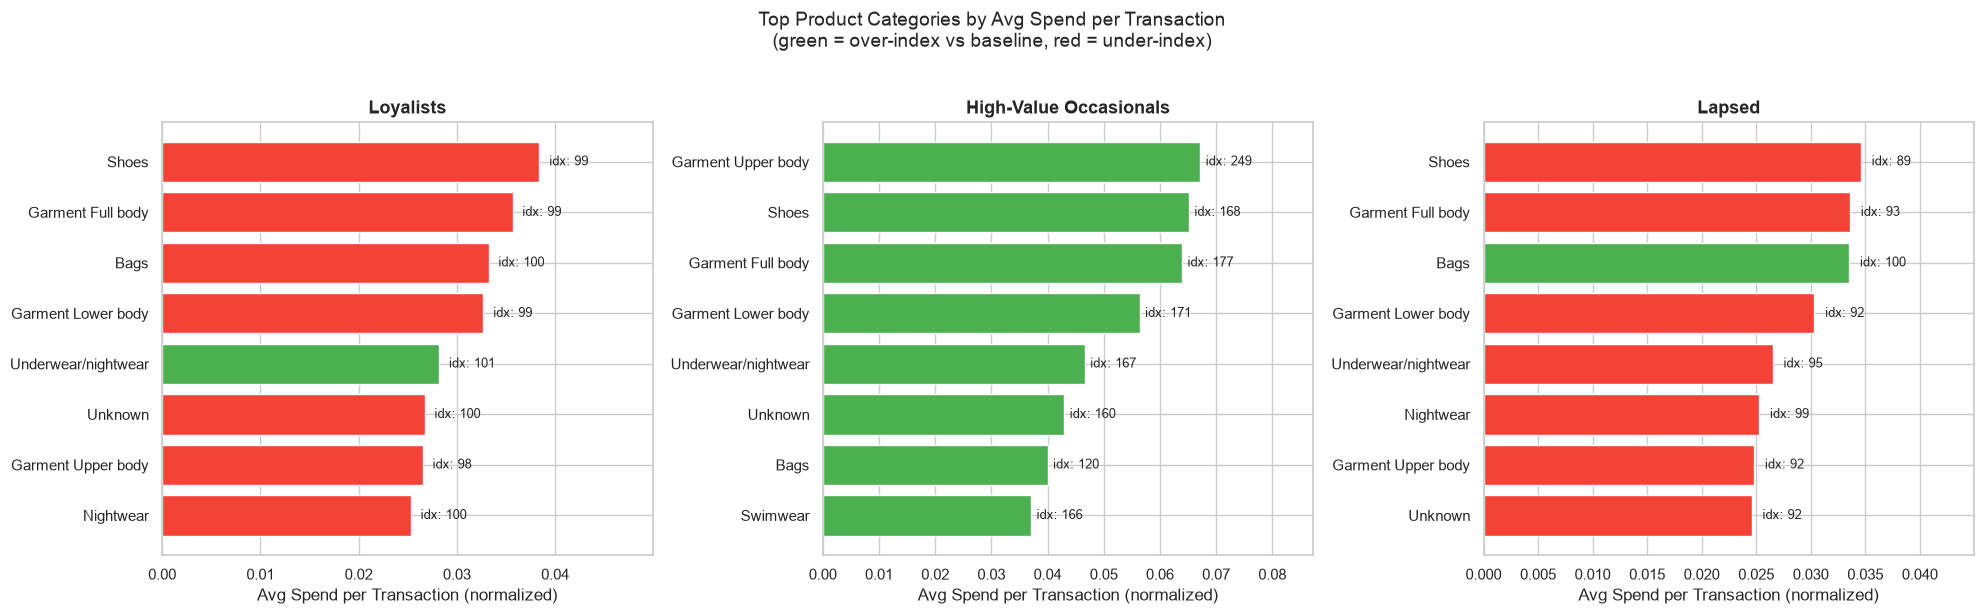

In [51]:
# Average spend per transaction by segment x product group
spend_seg = (transactions_seg
    .groupby(['segment', 'product_group_name'])
    .agg(avg_spend=('price', 'mean'))
    .reset_index()
)

# Overall average spend per category (baseline)
overall_spend = (transactions_seg
    .groupby('product_group_name')
    .agg(avg_spend_overall=('price', 'mean'))
    .reset_index()
)

spend_seg = spend_seg.merge(overall_spend, on='product_group_name')
spend_seg['index'] = (spend_seg['avg_spend'] / spend_seg['avg_spend_overall'] * 100).round(1)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

for ax, seg in zip(axes, segments):
    data = (spend_seg[spend_seg['segment'] == seg]
            .nlargest(top_n, 'avg_spend')
            .sort_values('avg_spend'))
    
    colors = ['#4CAF50' if x >= 100 else '#F44336' for x in data['index']]
    
    bars = ax.barh(data['product_group_name'], data['avg_spend'], color=colors)
    
    for bar, idx in zip(bars, data['index']):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'idx: {idx:.0f}', va='center', fontsize=9)
    
    ax.set_title(seg, fontsize=13, fontweight='bold')
    ax.set_xlabel('Avg Spend per Transaction (normalized)')
    ax.set_xlim(0, data['avg_spend'].max() * 1.3)

plt.suptitle('Top Product Categories by Avg Spend per Transaction\n(green = over-index vs baseline, red = under-index)',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

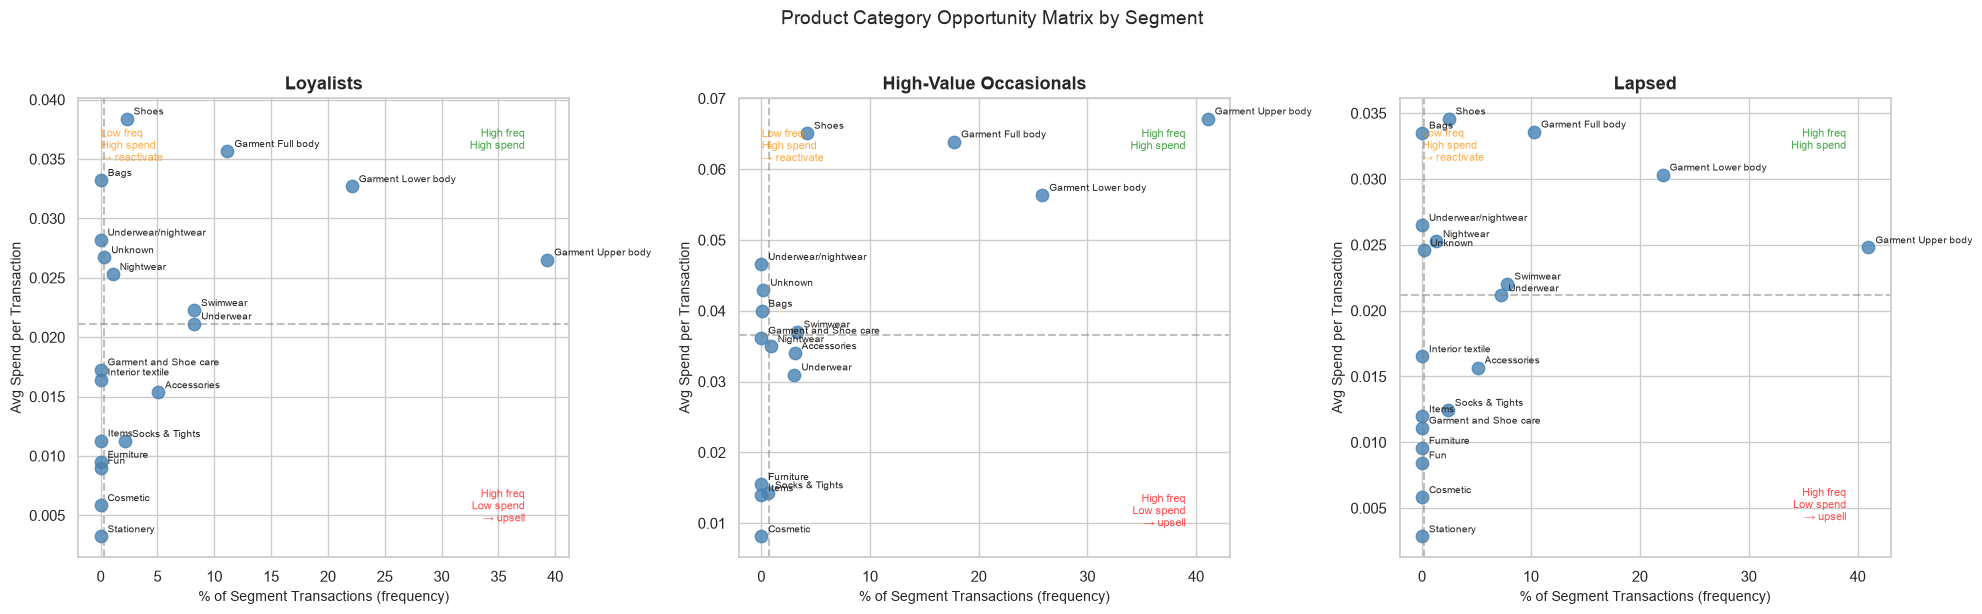

In [55]:
# Combine transaction share and avg spend per segment x category
opp = cat_seg[['segment', 'product_group_name', 'pct_of_segment']].merge(
    spend_seg[['segment', 'product_group_name', 'avg_spend', 'index']],
    on=['segment', 'product_group_name']
)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, seg in zip(axes, segments):
    data = opp[opp['segment'] == seg]
    
    scatter = ax.scatter(
        data['pct_of_segment'], 
        data['avg_spend'],
        s=80, alpha=0.8, color='steelblue'
    )
    
    # Label each point
    for _, row in data.iterrows():
        ax.annotate(row['product_group_name'], 
                    xy=(row['pct_of_segment'], row['avg_spend']),
                    xytext=(5, 3), textcoords='offset points', fontsize=7.5)
    
    # Quadrant lines at medians
    ax.axvline(data['pct_of_segment'].median(), color='gray', linestyle='--', alpha=0.5)
    ax.axhline(data['avg_spend'].median(), color='gray', linestyle='--', alpha=0.5)
    
    # Quadrant labels
    xmax = data['pct_of_segment'].max()
    ymax = data['avg_spend'].max()
    ymin = data['avg_spend'].min()
    xmed = data['pct_of_segment'].median()
    ymed = data['avg_spend'].median()
    
    ax.text(xmax * 0.95, ymax * 0.98, 'High freq\nHigh spend', ha='right', va='top',
            fontsize=8, color='green', alpha=0.7)
    ax.text(xmax * 0.95, ymin + 0.001, 'High freq\nLow spend\n→ upsell', ha='right', va='bottom',
            fontsize=8, color='red', alpha=0.7)
    ax.text(xmed * 0.05, ymax * 0.98, 'Low freq\nHigh spend\n→ reactivate', ha='left', va='top',
            fontsize=8, color='darkorange', alpha=0.7)
    
    ax.set_title(seg, fontsize=13, fontweight='bold')
    ax.set_xlabel('% of Segment Transactions (frequency)', fontsize=10)
    ax.set_ylabel('Avg Spend per Transaction', fontsize=10)

plt.suptitle('Product Category Opportunity Matrix by Segment', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Spend per Transaction by Category

High-Value Occasionals consistently over-index on spend per transaction across every 
category (index 165–249), while Loyalists and Lapsed customers cluster near the 
baseline (index ~90–100). This is not driven by category preferences — all three 
groups shop the same categories — but by the price point of items chosen within 
each category. High-Value Occasionals are buying premium; Loyalists and Lapsed 
customers are buying at or below average price points.

This raises a natural business question: given that Loyalists already shop 
frequently in the same categories as High-Value Occasionals, what would it be worth 
to shift their spend per transaction upward? To quantify this, we compute a revenue 
uplift estimate for each of the top 5 Loyalist categories. For each category, we 
calculate the spend gap between the two segments and multiply by the total number 
of Loyalist transactions in that category:

$$\text{uplift} = (\bar{spend}_{HVO} - \bar{spend}_{Loyalist}) \times n\_transactions_{Loyalist}$$

This gives us a normalized estimate of the additional revenue that would be 
generated if Loyalists matched High-Value Occasional spending behavior — holding 
transaction volume fixed.

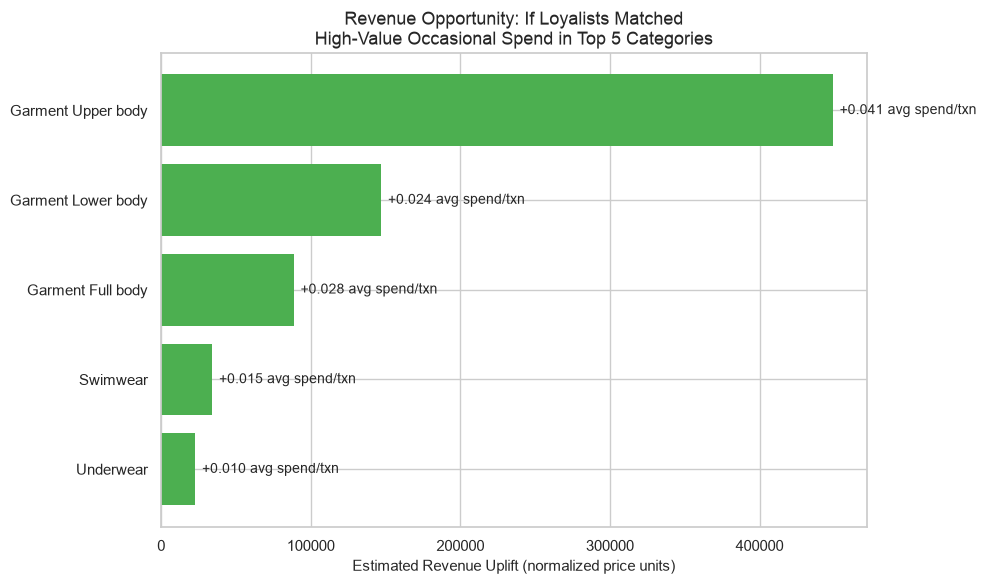

   product_group_name  loyalist_spend  hvo_spend  spend_gap  revenue_uplift
3           Underwear          0.0211     0.0310     0.0098      22844.8768
4            Swimwear          0.0223     0.0370     0.0148      34200.0357
2   Garment Full body          0.0357     0.0639     0.0282      88671.7266
1  Garment Lower body          0.0327     0.0564     0.0237     147143.6449
0  Garment Upper body          0.0265     0.0672     0.0406     449056.9265


In [54]:
# Get transaction counts per segment x category
txn_counts = (transactions_seg
    .groupby(['segment', 'product_group_name'])
    .size()
    .reset_index(name='n_transactions')
)

opp2 = opp.merge(txn_counts, on=['segment', 'product_group_name'])

# Get HVO and Loyalist spend side by side for top Loyalist categories
loyalist_top = (opp2[opp2['segment'] == 'Loyalists']
    .nlargest(5, 'pct_of_segment')[['product_group_name', 'avg_spend', 'n_transactions']]
    .rename(columns={'avg_spend': 'loyalist_spend', 'n_transactions': 'loyalist_txns'})
)

hvo_spend = (opp2[opp2['segment'] == 'High-Value Occasionals']
    [['product_group_name', 'avg_spend']]
    .rename(columns={'avg_spend': 'hvo_spend'})
)

uplift_df = loyalist_top.merge(hvo_spend, on='product_group_name')
uplift_df['spend_gap'] = uplift_df['hvo_spend'] - uplift_df['loyalist_spend']
uplift_df['revenue_uplift'] = uplift_df['spend_gap'] * uplift_df['loyalist_txns']
uplift_df = uplift_df.sort_values('revenue_uplift', ascending=True)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(uplift_df['product_group_name'], uplift_df['revenue_uplift'],
               color='#4CAF50', edgecolor='none')

for bar, gap in zip(bars, uplift_df['spend_gap']):
    ax.text(bar.get_width() + uplift_df['revenue_uplift'].max() * 0.01,
            bar.get_y() + bar.get_height()/2,
            f'+{gap:.3f} avg spend/txn', va='center', fontsize=10)

ax.set_xlabel('Estimated Revenue Uplift (normalized price units)', fontsize=11)
ax.set_title('Revenue Opportunity: If Loyalists Matched\nHigh-Value Occasional Spend in Top 5 Categories',
             fontsize=13)
plt.tight_layout()
plt.show()

print(uplift_df[['product_group_name', 'loyalist_spend', 'hvo_spend', 'spend_gap', 'revenue_uplift']].round(4))

### Revenue Uplift Opportunity

Garment Upper Body represents the single largest revenue opportunity: Loyalists 
transact in this category at nearly 17× the rate of High-Value Occasionals, but 
spend 0.04 normalized price units less per transaction. Closing even a fraction of 
this gap through targeted upsell recommendations would generate outsized returns 
relative to any other category intervention. The remaining categories — Garment 
Lower Body, Full Body, Swimwear, and Underwear — show meaningful but substantially 
smaller gaps, together accounting for less than half the Upper Body opportunity.

## Customer Attributes by Segment

We examine whether segment membership is associated with observable customer 
characteristics: age, newsletter subscription, and club membership status.

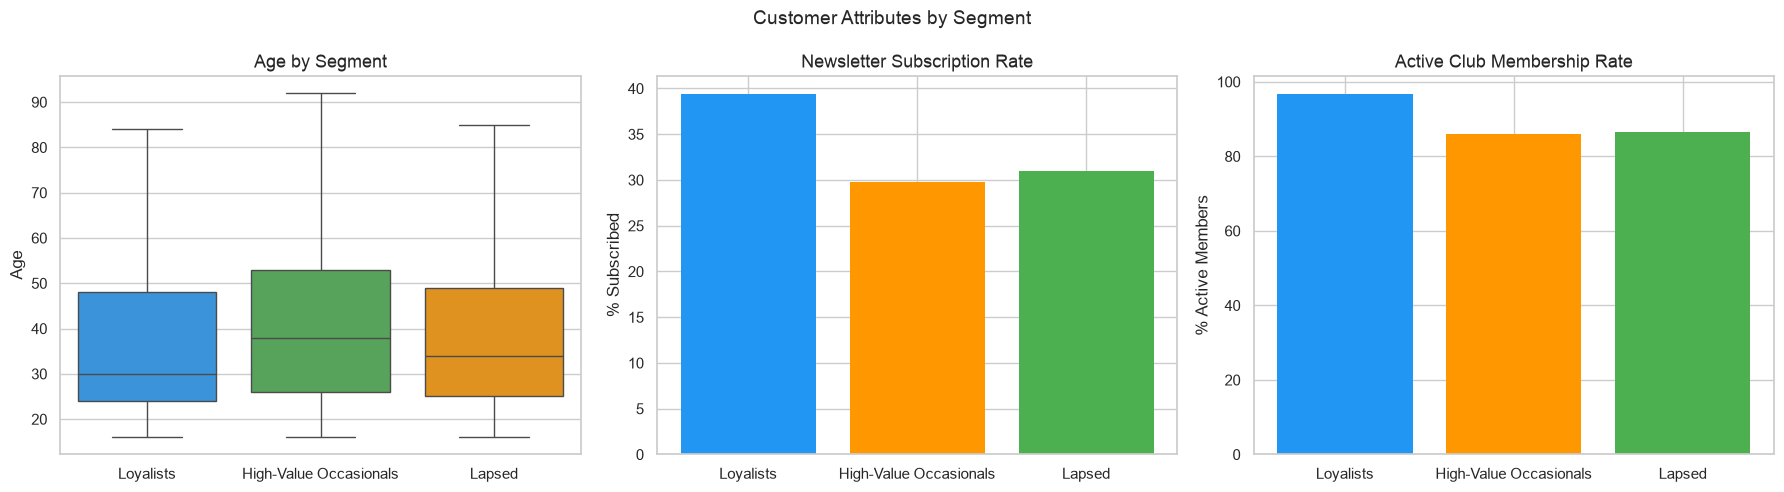

Newsletter rates:
                segment  pct_subscribed
             Loyalists       39.411714
High-Value Occasionals       29.778105
                Lapsed       30.971962

Club rates:
                segment  pct_active
             Loyalists   96.759271
High-Value Occasionals   86.043944
                Lapsed   86.509436


In [57]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age distribution
seg_order = ['Loyalists', 'High-Value Occasionals', 'Lapsed']
palette_seg = ['#2196F3', '#FF9800', '#4CAF50']

sns.boxplot(data=rfm.dropna(subset=['age']), x='segment', y='age',
            order=seg_order, hue='segment', palette=palette_seg,
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_title('Age by Segment', fontsize=13)
axes[0].set_xlabel('')
axes[0].set_ylabel('Age')

# Newsletter subscription rate
newsletter = (rfm.groupby('segment')['fashion_news_frequency']
    .apply(lambda x: (x != 'NONE').mean() * 100)
    .reindex(seg_order)
    .reset_index()
    .rename(columns={'fashion_news_frequency': 'pct_subscribed'})
)
axes[1].bar(newsletter['segment'], newsletter['pct_subscribed'],
            color=palette_seg, edgecolor='none')
axes[1].set_title('Newsletter Subscription Rate', fontsize=13)
axes[1].set_ylabel('% Subscribed')
axes[1].set_xlabel('')

# Club membership rate
club = (rfm.groupby('segment')['club_member_status']
    .apply(lambda x: (x == 'ACTIVE').mean() * 100)
    .reindex(seg_order)
    .reset_index()
    .rename(columns={'club_member_status': 'pct_active'})
)
axes[2].bar(club['segment'], club['pct_active'],
            color=palette_seg, edgecolor='none')
axes[2].set_title('Active Club Membership Rate', fontsize=13)
axes[2].set_ylabel('% Active Members')
axes[2].set_xlabel('')

plt.suptitle('Customer Attributes by Segment', fontsize=14)
plt.tight_layout()
plt.show()

print("Newsletter rates:\n", newsletter.to_string(index=False))
print("\nClub rates:\n", club.to_string(index=False))

## Customer Attribute Findings

Age differences across segments are modest and unlikely to drive targeting strategy. 
The stronger signals are behavioral: Loyalists are active club members at a 97% rate 
compared to ~86% for both other segments, and subscribe to the newsletter at 39% vs 
~30%. The direction of causality is unclear from observational data alone. In the 
following section we examine this association more carefully using propensity 
score matching to account for observable differences between subscribers and 
non-subscribers before drawing any conclusions.

In [58]:
rfm['segment'].value_counts()

segment
Loyalists                 831603
Lapsed                    411117
High-Value Occasionals    119561
Name: count, dtype: int64

## Conclusions: Customer Segmentation

K-means clustering on log-transformed, decorrelated RFM features identifies three 
distinct customer segments among H&M's 1.36M customers:

**Loyalists** (~61% of customers) are recent, high-frequency buyers who define the 
baseline spending pattern. They are disproportionately active club members (97%) and 
newsletter subscribers (39%). Their primary opportunity is upsell: they already shop 
frequently across all major categories, but spend below High-Value Occasional levels 
— particularly in Garment Upper Body, where closing the spend gap represents the 
single largest revenue opportunity identified in this analysis.

**High-Value Occasionals** (~30% of customers) shop infrequently but spend 
significantly more per transaction (index 165–249 across all categories). Their 
low frequency despite high engagement suggests a reactivation opportunity: targeted 
campaigns anchored to their high-affinity categories (Garment Upper Body, Full Body, 
Shoes) could increase visit frequency without requiring a change in spending behavior.

**Lapsed customers** (~9% of customers) have not purchased in over 500 days on 
average. Their shopping pattern — low frequency, moderate spend — structurally 
resembles High-Value Occasionals, suggesting they are not fundamentally different 
buyers but disengaged ones. Reactivation rather than behavior change is the 
appropriate intervention.

A key open question is the role of H&M's newsletter program in driving engagement. 
Loyalists subscribe at a higher rate (39% vs ~30%), but the direction of causality 
is unclear. In the following section we examine this association using propensity 
score matching to account for observable confounders.

## Newsletter Subscription and Purchasing Behavior

We examine whether newsletter subscription is associated with stronger purchasing 
behavior, using propensity score matching to account for the fact that subscribers 
and non-subscribers differ on observable characteristics (age, club membership, 
segment) that independently predict purchasing behavior.

### Step 1: Raw Comparison

We first examine the unadjusted difference in RFM metrics between subscribers 
and non-subscribers.

In [59]:
rfm['subscribed'] = (rfm['fashion_news_frequency'] != 'NONE').astype(int)

raw = rfm.groupby('subscribed')[['recency', 'frequency', 'monetary']].median()
raw.index = ['Not Subscribed', 'Subscribed']
print(raw.round(3))

                recency  frequency  monetary
Not Subscribed    172.0        8.0     0.026
Subscribed        108.0       12.0     0.026


### Step 2: Covariate Balance Check

Before matching, we check whether subscribers and non-subscribers differ on 
age and club membership — two characteristics associated with both subscription 
likelihood and purchasing behavior.

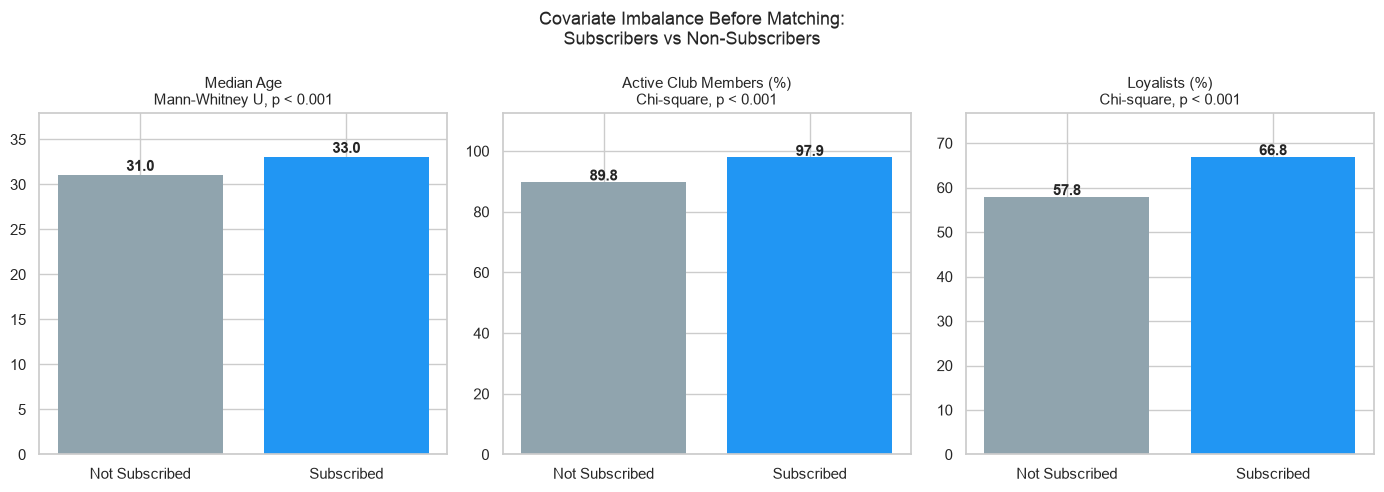

In [65]:
from scipy.stats import chi2_contingency

# Mann-Whitney for age
age_sub = rfm[rfm['subscribed'] == 1]['age'].dropna()
age_nonsub = rfm[rfm['subscribed'] == 0]['age'].dropna()
_, p_age = stats.mannwhitneyu(age_sub, age_nonsub, alternative='two-sided')

# Chi-square for club membership
club_ct = pd.crosstab(rfm['subscribed'], rfm['club_member_status'] == 'ACTIVE')
_, p_club, _, _ = chi2_contingency(club_ct)

# Chi-square for segment
seg_ct = pd.crosstab(rfm['subscribed'], rfm['segment'] == 'Loyalists')
_, p_seg, _, _ = chi2_contingency(seg_ct)

balance = rfm.groupby('subscribed').agg(
    median_age=('age', 'median'),
    pct_club_active=('club_member_status', lambda x: (x == 'ACTIVE').mean() * 100),
    pct_loyalist=('segment', lambda x: (x == 'Loyalists').mean() * 100),
).round(2)
balance.index = ['Not Subscribed', 'Subscribed']

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

vars_to_plot = ['median_age', 'pct_club_active', 'pct_loyalist']
base_labels = ['Median Age', 'Active Club Members (%)', 'Loyalists (%)']
p_values = [p_age, p_club, p_seg]
tests = ['Mann-Whitney U', 'Chi-square', 'Chi-square']

for ax, var, label, p, test in zip(axes, vars_to_plot, base_labels, p_values, tests):
    p_str = 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
    ax.bar(balance.index, balance[var],
           color=['#90A4AE', '#2196F3'], edgecolor='none')
    for i, val in enumerate(balance[var]):
        ax.text(i, val + 0.5, f'{val:.1f}', ha='center', fontsize=11, fontweight='bold')
    ax.set_title(f'{label}\n{test}, {p_str}', fontsize=11)
    ax.set_ylabel('')
    ax.set_ylim(0, balance[var].max() * 1.15)

plt.suptitle('Covariate Imbalance Before Matching:\nSubscribers vs Non-Subscribers', fontsize=13)
plt.tight_layout()
plt.show()

In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

# Prepare matching features
psm_df = rfm[['customer_id', 'subscribed', 'age', 
              'club_member_status', 'segment',
              'recency', 'frequency', 'monetary']].dropna().copy()

psm_df['club_active'] = (psm_df['club_member_status'] == 'ACTIVE').astype(int)
psm_df = pd.get_dummies(psm_df, columns=['segment'], drop_first=True)

feature_cols = ['age', 'club_active'] + [c for c in psm_df.columns if c.startswith('segment_')]

# Fit propensity score model
lr_ps = LogisticRegression(max_iter=1000)
lr_ps.fit(psm_df[feature_cols], psm_df['subscribed'])
psm_df['propensity'] = lr_ps.predict_proba(psm_df[feature_cols])[:, 1]

# Match each subscriber to nearest non-subscriber
subscribers = psm_df[psm_df['subscribed'] == 1].copy()
non_subscribers = psm_df[psm_df['subscribed'] == 0].copy()

nn = NearestNeighbors(n_neighbors=1)
nn.fit(non_subscribers[['propensity']])
distances, indices = nn.kneighbors(subscribers[['propensity']])

matched_controls = non_subscribers.iloc[indices.flatten()].copy()
matched_treated = subscribers.copy()

print(f"Matched sample: {len(matched_treated):,} subscriber-control pairs")
print(f"\nBalance after matching:")
print(pd.DataFrame({
    'Subscribed': matched_treated[['age', 'club_active', 'propensity']].mean(),
    'Not Subscribed': matched_controls[['age', 'club_active', 'propensity']].mean()
}).round(3))

Matched sample: 486,934 subscriber-control pairs

Balance after matching:
             Subscribed  Not Subscribed
age              37.064          37.064
club_active       0.984           0.984
propensity        0.381           0.381


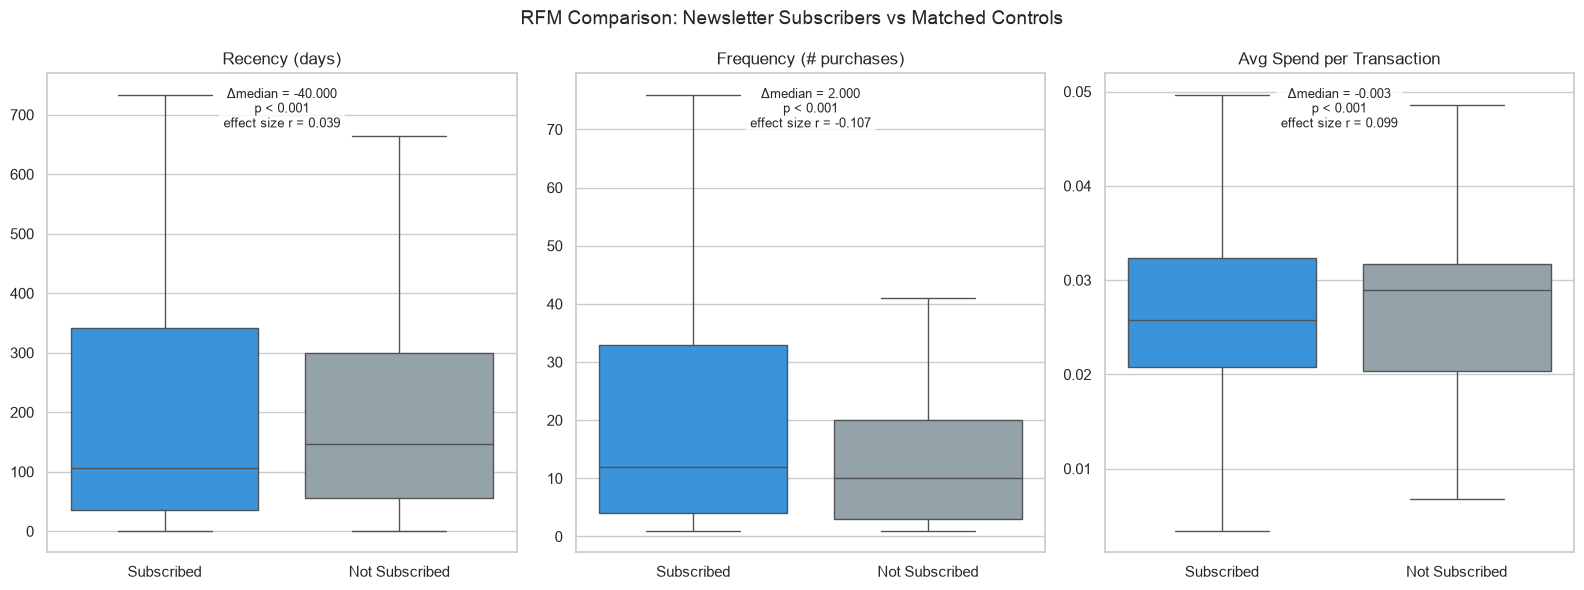

In [67]:
from scipy import stats

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

metrics = ['recency', 'frequency', 'monetary']
titles = ['Recency (days)', 'Frequency (# purchases)', 'Avg Spend per Transaction']

for ax, metric, title in zip(axes, metrics, titles):
    treated_vals = matched_treated[metric].values
    control_vals = matched_controls[metric].values
    
    # Mann-Whitney U test
    stat, p = stats.mannwhitneyu(treated_vals, control_vals, alternative='two-sided')
    
    # Effect size: rank-biserial correlation
    n1, n2 = len(treated_vals), len(control_vals)
    effect_size = 1 - (2 * stat) / (n1 * n2)
    
    # Median difference
    med_diff = np.median(treated_vals) - np.median(control_vals)
    
    # Plot
    plot_df = pd.DataFrame({
        'value': np.concatenate([treated_vals, control_vals]),
        'group': ['Subscribed'] * n1 + ['Not Subscribed'] * n2
    })
    
    sns.boxplot(data=plot_df, x='group', y='value',
                hue='group', palette=['#2196F3', '#90A4AE'],
                legend=False, showfliers=False, ax=ax)
    
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('')
    
    # Annotate with stats
    p_str = f'p < 0.001' if p < 0.001 else f'p = {p:.3f}'
    ax.text(0.5, 0.97,
            f'Δmedian = {med_diff:.3f}\n{p_str}\neffect size r = {effect_size:.3f}',
            transform=ax.transAxes, ha='center', va='top', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

plt.suptitle('RFM Comparison: Newsletter Subscribers vs Matched Controls',
             fontsize=14)
plt.tight_layout()
plt.show()

### Newsletter Effect After Matching

After propensity score matching on age, club membership, and segment, newsletter 
subscribers show modest but statistically significant differences across all three 
RFM dimensions. Subscribers purchase more recently (Δmedian = -40 days, r = 0.039) 
and more frequently (Δmedian = +2 purchases, r = 0.107), but spend slightly less 
per transaction (Δmedian = -0.003, r = 0.099). All effects are small in magnitude.

These results suggest the newsletter is associated with engagement frequency but not 
spend quality. The practical implication is that newsletter campaigns may be effective 
for driving return visits but are unlikely on their own to shift customers toward 
higher price-point purchases — a separate upsell strategy would be needed for that.

## Overall Conclusions

This analysis segmented 1.36M H&M customers into three behaviorally distinct groups 
using RFM features, with preprocessing choices motivated by the data structure: 
monetary was defined as average spend per transaction (rather than total spend) to 
avoid collinearity with frequency, and recency was residualized on frequency to 
remove their spurious negative correlation.

**Key findings:**

1. **Three distinct customer segments emerge from the data.** Loyalists (61%) are 
   recent, high-frequency buyers who define the baseline. High-Value Occasionals (9%) 
   shop infrequently but spend significantly more per transaction. Lapsed customers 
   (30%) have not purchased in over 500 days and show no strong category signal.

2. **The primary revenue opportunity lies in upselling Loyalists in Garment Upper 
   Body.** Despite transacting in this category at 17× the rate of High-Value 
   Occasionals, Loyalists spend 0.04 normalized price units less per transaction — 
   the largest single revenue gap identified across all segments and categories.

3. **Lapsed customers structurally resemble High-Value Occasionals.** Their low 
   frequency and moderate spend per visit suggest they are disengaged rather than 
   fundamentally different buyers. Reactivation campaigns anchored to their 
   historical category behavior are the appropriate intervention.

4. **Newsletter subscription is associated with modest engagement gains but not 
   spend quality.** After propensity score matching, subscribers purchase more 
   recently and frequently (effect sizes r ≈ 0.04–0.11) but spend slightly less 
   per transaction. Club membership is a stronger differentiator than newsletter 
   subscription across all segments.

**Limitations:** Prices in this dataset are normalized and do not reflect real 
currency values, so revenue uplift estimates are relative rather than absolute. 
Causal claims about newsletter subscription cannot be made from observational data 
alone — propensity score matching controls for observable confounders but cannot 
rule out unobserved ones.

In [68]:
rfm_export = rfm[['customer_id', 'recency', 'recency_resid', 'frequency', 
                   'monetary', 'cluster', 'segment', 'age', 
                   'club_member_status', 'fashion_news_frequency',
                   'pc1', 'pc2']].copy()

rfm_export.to_csv('data/rfm_clusters.csv', index=False)
print(f"Exported {len(rfm_export):,} rows to data/rfm_clusters.csv")

Exported 1,362,281 rows to data/rfm_clusters.csv
